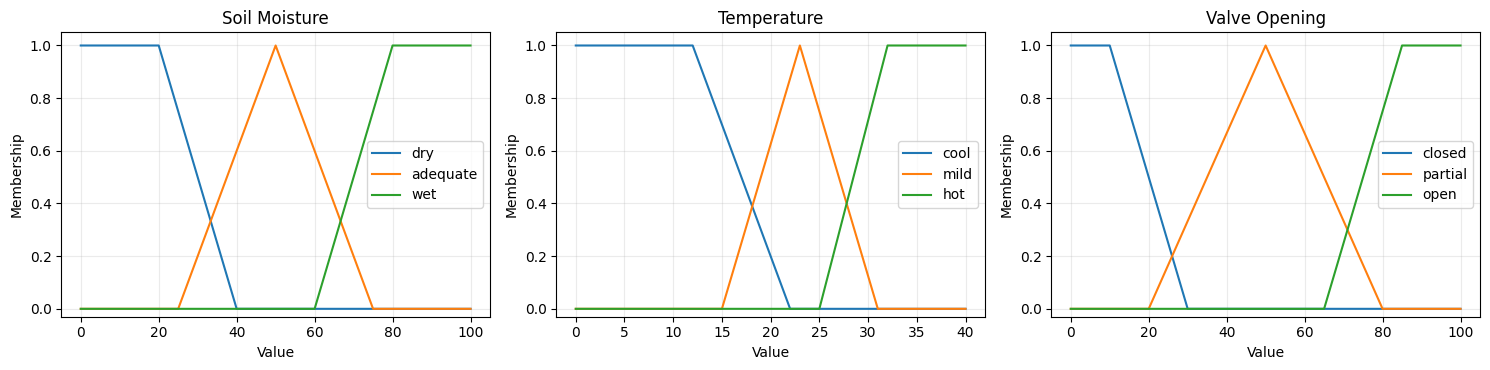

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

soil = ctrl.Antecedent(np.arange(0, 101, 1), "soil_moisture")
temperature = ctrl.Antecedent(np.arange(0, 41, 1), "temperature")
valve = ctrl.Consequent(np.arange(0, 101, 1), "valve_opening")

soil["dry"] = fuzz.trapmf(soil.universe, [0, 0, 20, 40])
soil["adequate"] = fuzz.trimf(soil.universe, [25, 50, 75])
soil["wet"] = fuzz.trapmf(soil.universe, [60, 80, 100, 100])

temperature["cool"] = fuzz.trapmf(temperature.universe, [0, 0, 12, 22])
temperature["mild"] = fuzz.trimf(temperature.universe, [15, 23, 31])
temperature["hot"] = fuzz.trapmf(temperature.universe, [25, 32, 40, 40])

valve["closed"] = fuzz.trapmf(valve.universe, [0, 0, 10, 30])
valve["partial"] = fuzz.trimf(valve.universe, [20, 50, 80])
valve["open"] = fuzz.trapmf(valve.universe, [65, 85, 100, 100])

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for variable, ax in zip((soil, temperature, valve), axes):
    for label in variable.terms:
        ax.plot(variable.universe, variable[label].mf, label=label)
    ax.set(title=variable.label.replace("_", " ").title(), xlabel="Value", ylabel="Membership")
    ax.set_ylim(-0.03, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()
plt.tight_layout()
plt.show()

In [2]:
rules = [
    ctrl.Rule(soil["dry"], valve["open"], label="dry soil needs water"),
    ctrl.Rule(soil["adequate"] & temperature["hot"], valve["partial"], label="adequate and hot"),
    ctrl.Rule(soil["adequate"] & (temperature["mild"] | temperature["cool"]), valve["closed"], label="adequate and not hot"),
    ctrl.Rule(soil["wet"], valve["closed"], label="wet soil avoids watering"),
]

irrigation_system = ctrl.ControlSystem(rules)
print(f"Controller created with {len(rules)} rules.")

Controller created with 4 rules.


In [3]:
cases = [
    ("Dry bed, mild morning", 18, 20),
    ("Moderate moisture, hot afternoon", 48, 34),
    ("Adequate moisture, mild day", 52, 22),
    ("Wet bed after watering", 88, 27),
]

results = []
for name, moisture, air_temp in cases:
    simulation = ctrl.ControlSystemSimulation(irrigation_system)
    simulation.input["soil_moisture"] = moisture
    simulation.input["temperature"] = air_temp
    simulation.compute()
    results.append({
        "Scenario": name,
        "Soil moisture (%)": moisture,
        "Air temperature (°C)": air_temp,
        "Recommended valve opening (%)": round(simulation.output["valve_opening"], 1),
    })

for result in results:
    print(f"{result['Scenario']:<38} | soil {result['Soil moisture (%)']:>3}% | "
          f"{result['Air temperature (°C)']:>2}°C | valve {result['Recommended valve opening (%)']:>5.1f}%")

Dry bed, mild morning                  | soil  18% | 20°C | valve  86.8%
Moderate moisture, hot afternoon       | soil  48% | 34°C | valve  50.0%
Adequate moisture, mild day            | soil  52% | 22°C | valve  11.2%
Wet bed after watering                 | soil  88% | 27°C | valve  10.8%


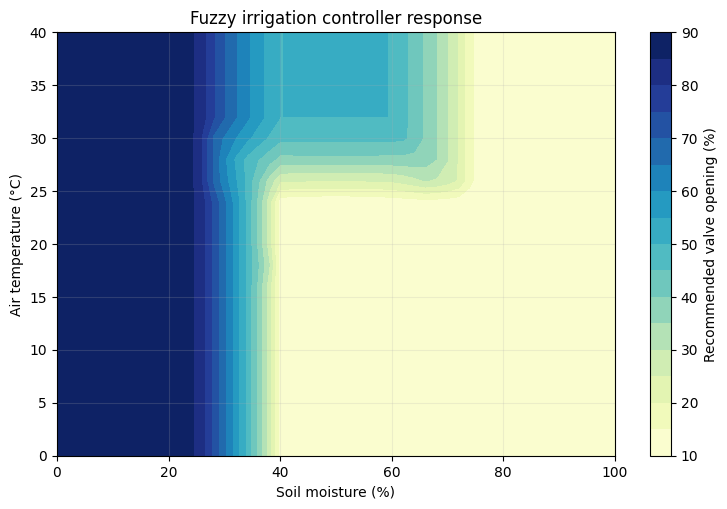

In [4]:
moisture_values = np.arange(0, 101, 2)
temperature_values = np.arange(0, 41, 2)
surface = np.zeros((len(temperature_values), len(moisture_values)))

for row, air_temp in enumerate(temperature_values):
    for col, moisture in enumerate(moisture_values):
        simulation = ctrl.ControlSystemSimulation(irrigation_system)
        simulation.input["soil_moisture"] = moisture
        simulation.input["temperature"] = air_temp
        simulation.compute()
        surface[row, col] = simulation.output["valve_opening"]

fig, ax = plt.subplots(figsize=(9, 5.5))
contour = ax.contourf(moisture_values, temperature_values, surface, levels=15, cmap="YlGnBu")
fig.colorbar(contour, ax=ax, label="Recommended valve opening (%)")
ax.set(xlabel="Soil moisture (%)", ylabel="Air temperature (°C)",
       title="Fuzzy irrigation controller response")
ax.grid(alpha=0.2)
plt.show()

The controller should recommend a high opening when the bed is dry, reduce watering as moisture rises, and suppress watering for wet soil. Hot conditions can raise the recommendation when moisture is only adequate. The memberships make transitions gradual rather than switching abruptly at a single threshold.

For a real greenhouse, validate sensor calibration and soil-specific moisture ranges, include rainfall or recent irrigation, and tune the rules against observed plant response.